# Test: chart colour palettes

The bar/line charts (radiative budget, water budget, paired years, monthly chains) take their colours from four module constants in `forcing_maps.py`: `TERM_STYLE` (Ghan terms), `WATER_BUDGET_COLORS`, `PERIOD_COLORS` (PD / FUT), `REGION_COLORS`. Each option below swaps them; the maps (RdBu_r diverging) are not affected.

**Fixed roles in every option:** *total* = dark grey `#333333` (it is the sum, so it stays neutral), *albedo proxy* = hatched white, *residual* = grey. Water budget order: P, ET, R_liq, R_ice, ΔTWS, residual.

| Option | Source | Character |
|---|---|---|
| A | current | muted tab-like |
| B | Okabe & Ito (2008) | the standard colour-blind-safe set |
| C | Paul Tol "bright" | clear, medium saturation, CVD-safe |
| D | Paul Tol "muted" | soft, print-friendly, CVD-safe |
| E | Paul Tol "vibrant" | strong, CVD-safe |
| F | dataviz-skill reference palette | modern, saturated |

**Colour-blind check (computed, not eyeballed):** for each palette, the smallest colour difference ΔE (OKLab × 100) between any two colours of the same chart, for normal vision and simulated deuteranopia / protanopia / tritanopia (Machado et al. 2009, severity 1). Target ≥ 8 under CVD and ≥ 15 for normal vision; lower = two series can be confused. (The dataviz skill's own validator needs `node`, not installed here; this is the same OKLab ΔE idea, re-implemented.)

Data: 2001–2009 archive (`2001-2009-pre-co2-fix/`). Outputs: `test_palettes_outputs/<figure>_<option>.png`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
# 2001-2009 processed files were archived on 2026-10-28 (CLAUDE.md, run-version rule step 2 (i))
fm.POSTPROCESSED_DIR = fm.POSTPROCESSED_DIR / "2001-2009-pre-co2-fix"
OUT = Path.cwd() / "test_palettes_outputs"
OUT.mkdir(exist_ok=True)
years = dict(start_year=2001, end_year=2009, save=False)

PALETTES = {
 "A_current": {
  "dir": "#d08a2e",
  "cloud": "#3b75af",
  "rest": "#c44e52",
  "PD": "#3b75af",
  "FUT": "#c44e52",
  "water": [
   "#3b75af",
   "#4f9e5a",
   "#d08a2e",
   "#7fc6d6",
   "#8c6bb1",
   "#9a9a9a"
  ]
 },
 "B_OkabeIto": {
  "dir": "#E69F00",
  "cloud": "#0072B2",
  "rest": "#009E73",
  "PD": "#0072B2",
  "FUT": "#D55E00",
  "water": [
   "#0072B2",
   "#009E73",
   "#56B4E9",
   "#CC79A7",
   "#E69F00",
   "#999999"
  ]
 },
 "C_TolBright": {
  "dir": "#CCBB44",
  "cloud": "#4477AA",
  "rest": "#228833",
  "PD": "#4477AA",
  "FUT": "#EE6677",
  "water": [
   "#4477AA",
   "#228833",
   "#66CCEE",
   "#AA3377",
   "#CCBB44",
   "#BBBBBB"
  ]
 },
 "D_TolMuted": {
  "dir": "#DDCC77",
  "cloud": "#88CCEE",
  "rest": "#CC6677",
  "PD": "#332288",
  "FUT": "#CC6677",
  "water": [
   "#332288",
   "#117733",
   "#88CCEE",
   "#AA4499",
   "#DDCC77",
   "#BBBBBB"
  ]
 },
 "E_TolVibrant": {
  "dir": "#EE7733",
  "cloud": "#0077BB",
  "rest": "#009988",
  "PD": "#0077BB",
  "FUT": "#CC3311",
  "water": [
   "#0077BB",
   "#009988",
   "#33BBEE",
   "#EE3377",
   "#EE7733",
   "#BBBBBB"
  ]
 },
 "F_SkillDefault": {
  "dir": "#eda100",
  "cloud": "#2a78d6",
  "rest": "#eb6834",
  "PD": "#2a78d6",
  "FUT": "#e34948",
  "water": [
   "#2a78d6",
   "#008300",
   "#1baf7a",
   "#6250d6",
   "#eda100",
   "#9a9a9a"
  ]
 }
}
NAMES = {
 "A_current": "A: current",
 "B_OkabeIto": "B: Okabe–Ito (colour-blind safe classic)",
 "C_TolBright": "C: Paul Tol 'bright'",
 "D_TolMuted": "D: Paul Tol 'muted' (soft)",
 "E_TolVibrant": "E: Paul Tol 'vibrant'",
 "F_SkillDefault": "F: dataviz reference palette"
}
DEFAULTS = dict(TERM_STYLE=dict(fm.TERM_STYLE), WATER_BUDGET_COLORS=list(fm.WATER_BUDGET_COLORS),
                PERIOD_COLORS=dict(fm.PERIOD_COLORS), REGION_COLORS=dict(fm.REGION_COLORS))

def apply(p):
    fm.TERM_STYLE = {**DEFAULTS["TERM_STYLE"], "dir": ("aerosol-direct", p["dir"]),
                     "cloud": ("cloud", p["cloud"]), "rest": ("rest", p["rest"])}
    fm.WATER_BUDGET_COLORS = p["water"]
    fm.PERIOD_COLORS = {"PD": p["PD"], "FUT": p["FUT"]}
    fm.REGION_COLORS = {"modified cells": p["FUT"], "unmodified land ≥45°N": p["PD"]}

def restore():
    for k, v in DEFAULTS.items():
        setattr(fm, k, v)

In [2]:
# --- colour-blind check: sRGB -> (CVD simulation) -> OKLab, smallest pairwise ΔE x 100
MACHADO = {   # Machado, Oliveira & Fernandes (2009), severity 1.0, linear RGB
    "deutan": np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
    "protan": np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    "tritan": np.array([[1.255528, -0.076749, -0.178779], [-0.078411, 0.930809, 0.147602], [0.004733, 0.691367, 0.303900]]),
}

def to_linear(c):
    c = np.array(to_rgb(c))
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def oklab(lin):
    lms = np.array([[0.4122214708, 0.5363325363, 0.0514459929], [0.2119034982, 0.6806995451, 0.1073969566],
                    [0.0883024619, 0.2817188376, 0.6299787005]]) @ np.clip(lin, 0, 1)
    return np.array([[0.2104542553, 0.7936177850, -0.0040720468], [1.9779984951, -2.4285922050, 0.4505937099],
                     [0.0259040371, 0.7827717662, -0.8086757660]]) @ np.cbrt(lms)

def worst_pair(colors, vision):
    lab = {c: oklab(MACHADO[vision] @ to_linear(c) if vision != "normal" else to_linear(c)) for c in colors}
    return min((100 * np.linalg.norm(lab[a] - lab[b]), f"{a}–{b}") for a, b in itertools.combinations(colors, 2))

rows = []
for name, p in PALETTES.items():
    groups = {"Ghan terms (+ total #333333)": ["#333333", p["dir"], p["cloud"], p["rest"]],
              "water budget": p["water"], "PD / FUT": [p["PD"], p["FUT"]]}
    for group, colors in groups.items():
        r = dict(option=name, chart=group)
        for v in ("normal", "deutan", "protan", "tritan"):
            de, pair = worst_pair(colors, v)
            r[v] = round(de, 1)
            r[f"{v} pair"] = pair
        rows.append(r)
cvd = pd.DataFrame(rows)
flag = lambda v: "color: #b00; font-weight: bold" if v < 8 else ""
cvd[["option", "chart", "normal", "deutan", "protan", "tritan"]].style.map(flag, subset=["deutan", "protan", "tritan"]).format(precision=1)

,option,chart,normal,deutan,protan,tritan
0,A_current,Ghan terms (+ total #333333),15.9,12.4,14.3,12.5
1,A_current,water budget,10.7,4.9,0.3,8.4
2,A_current,PD / FUT,24.0,18.3,14.3,28.9
3,B_OkabeIto,Ghan terms (+ total #333333),18.7,18.1,11.4,8.6
4,B_OkabeIto,water budget,11.8,1.9,5.4,8.5
5,B_OkabeIto,PD / FUT,31.2,28.2,21.9,30.9
6,C_TolBright,Ghan terms (+ total #333333),20.0,17.4,18.4,3.3
7,C_TolBright,water budget,10.6,7.9,7.2,3.3
8,C_TolBright,PD / FUT,26.9,21.3,10.3,32.9
9,D_TolMuted,Ghan terms (+ total #333333),17.8,18.1,16.6,16.0


In [3]:
# tables needed by the charts (same calls as the analysis notebooks)
budget = fm.radiative_budget_table(start_year=2001, end_year=2009)
water = fm.water_budget_table(2001, 2009)

def palette_figures(name):
    apply(PALETTES[name])
    try:
        for tag, make in [("radiative_budget", lambda: fm.make_radiative_budget_figure(budget, **years)),
                          ("water_budget", lambda: fm.make_water_budget_figure(water, "LCC-CTRL", **years)),
                          ("paired_years", lambda: fm.make_paired_years_figure(budget, band="NET", **years))]:
            fig, _ = make()
            fig.savefig(OUT / f"{tag}_{name}.png", dpi=110, bbox_inches="tight")
            plt.show(); plt.close(fig)
    finally:
        restore()

Closure before rounding: Ghan terms vs total 1.1e-07, contrasts 4.4e-04 W m-2


## A: current

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight semibold, now using 700.


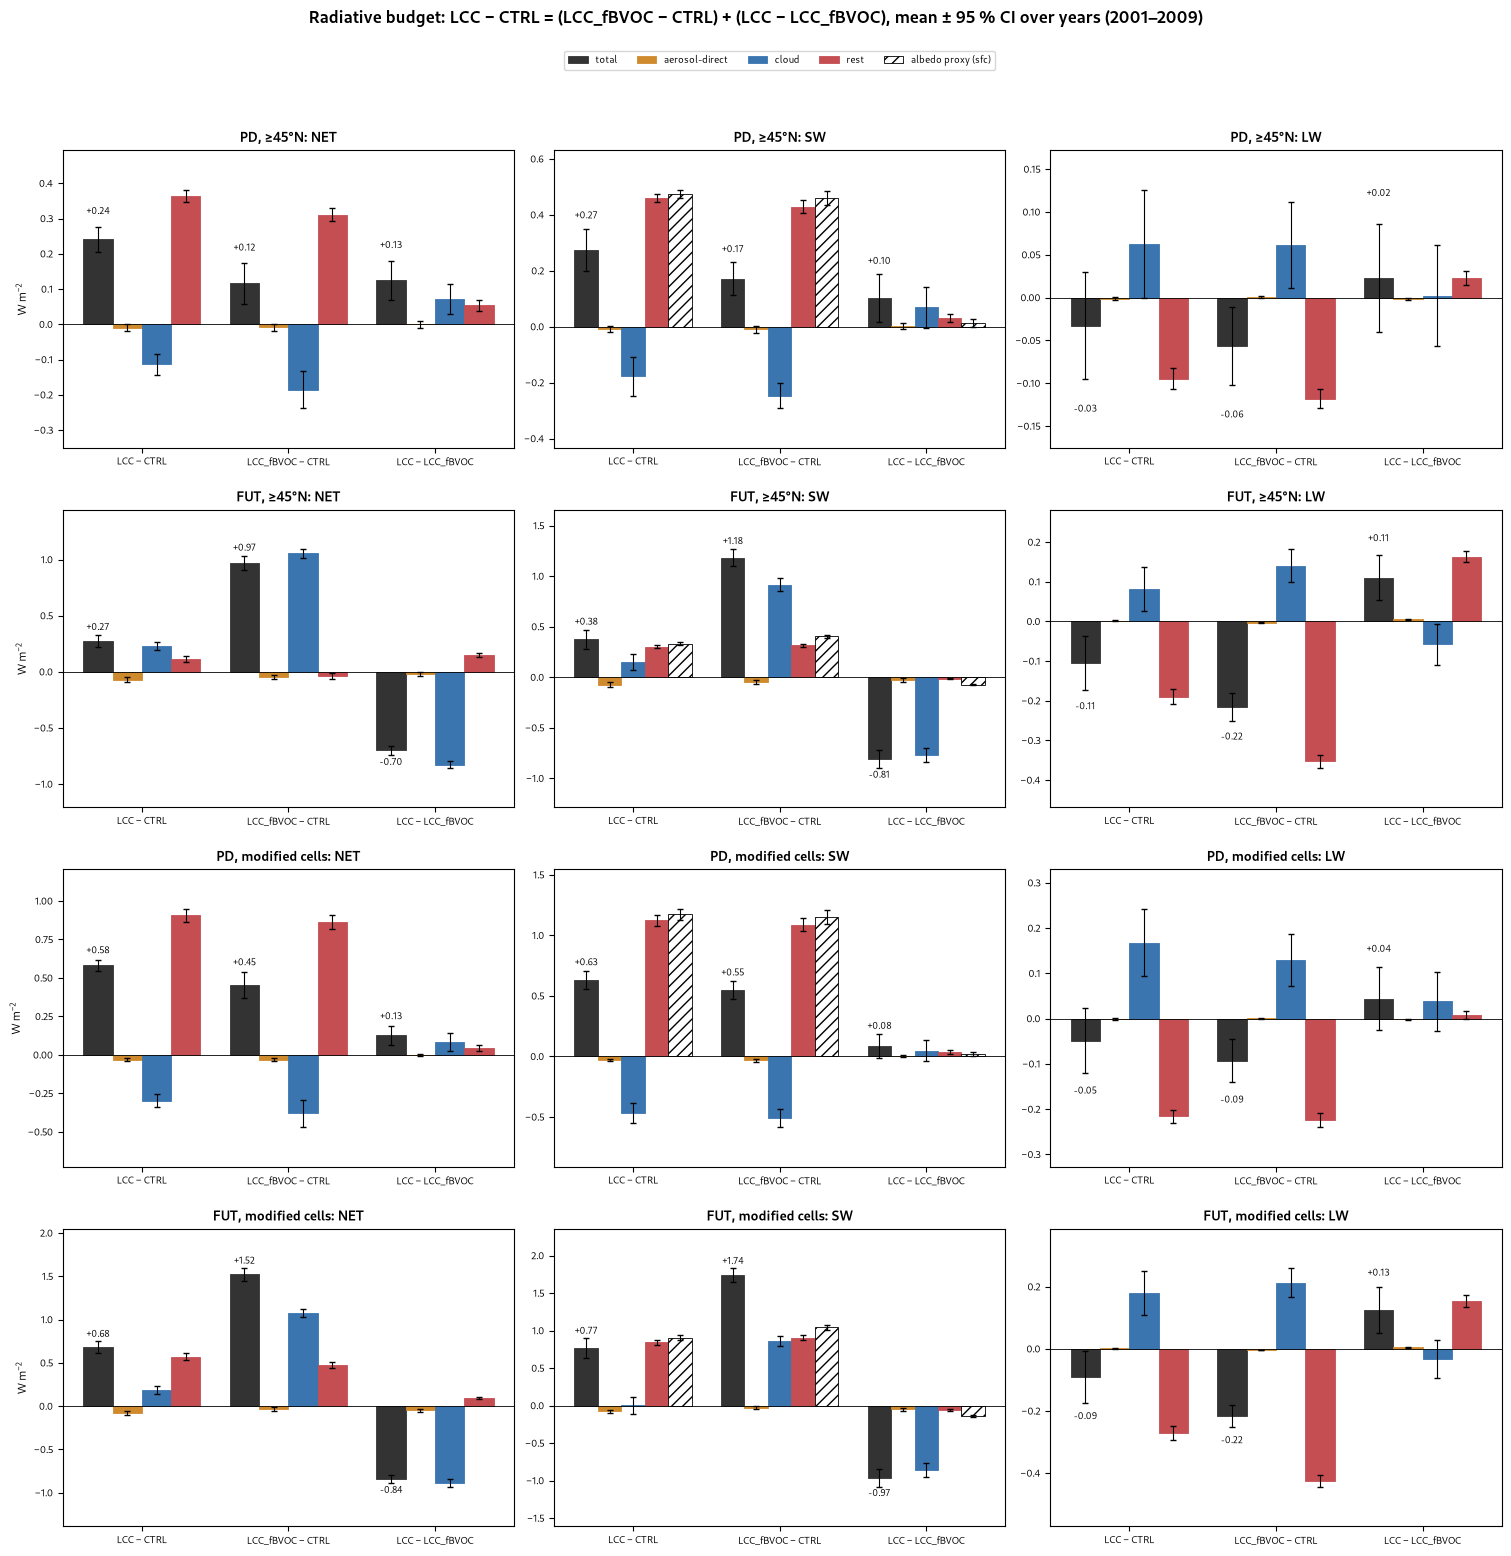

findfont: Failed to find font weight semibold, now using 700.


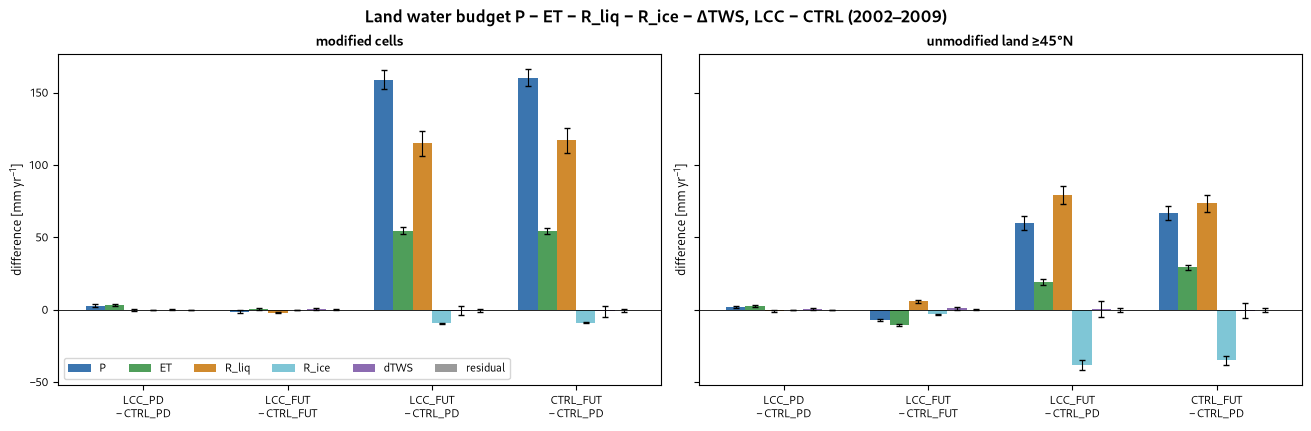

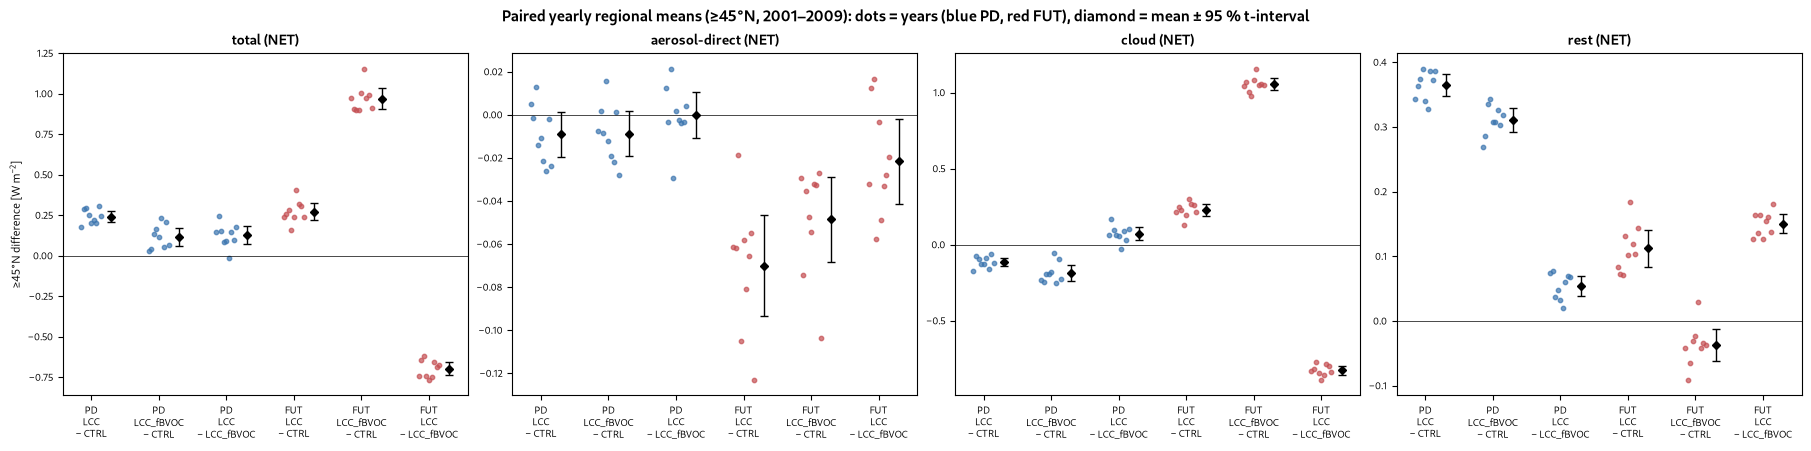

In [4]:
palette_figures("A_current")

## B: Okabe–Ito (colour-blind safe classic)

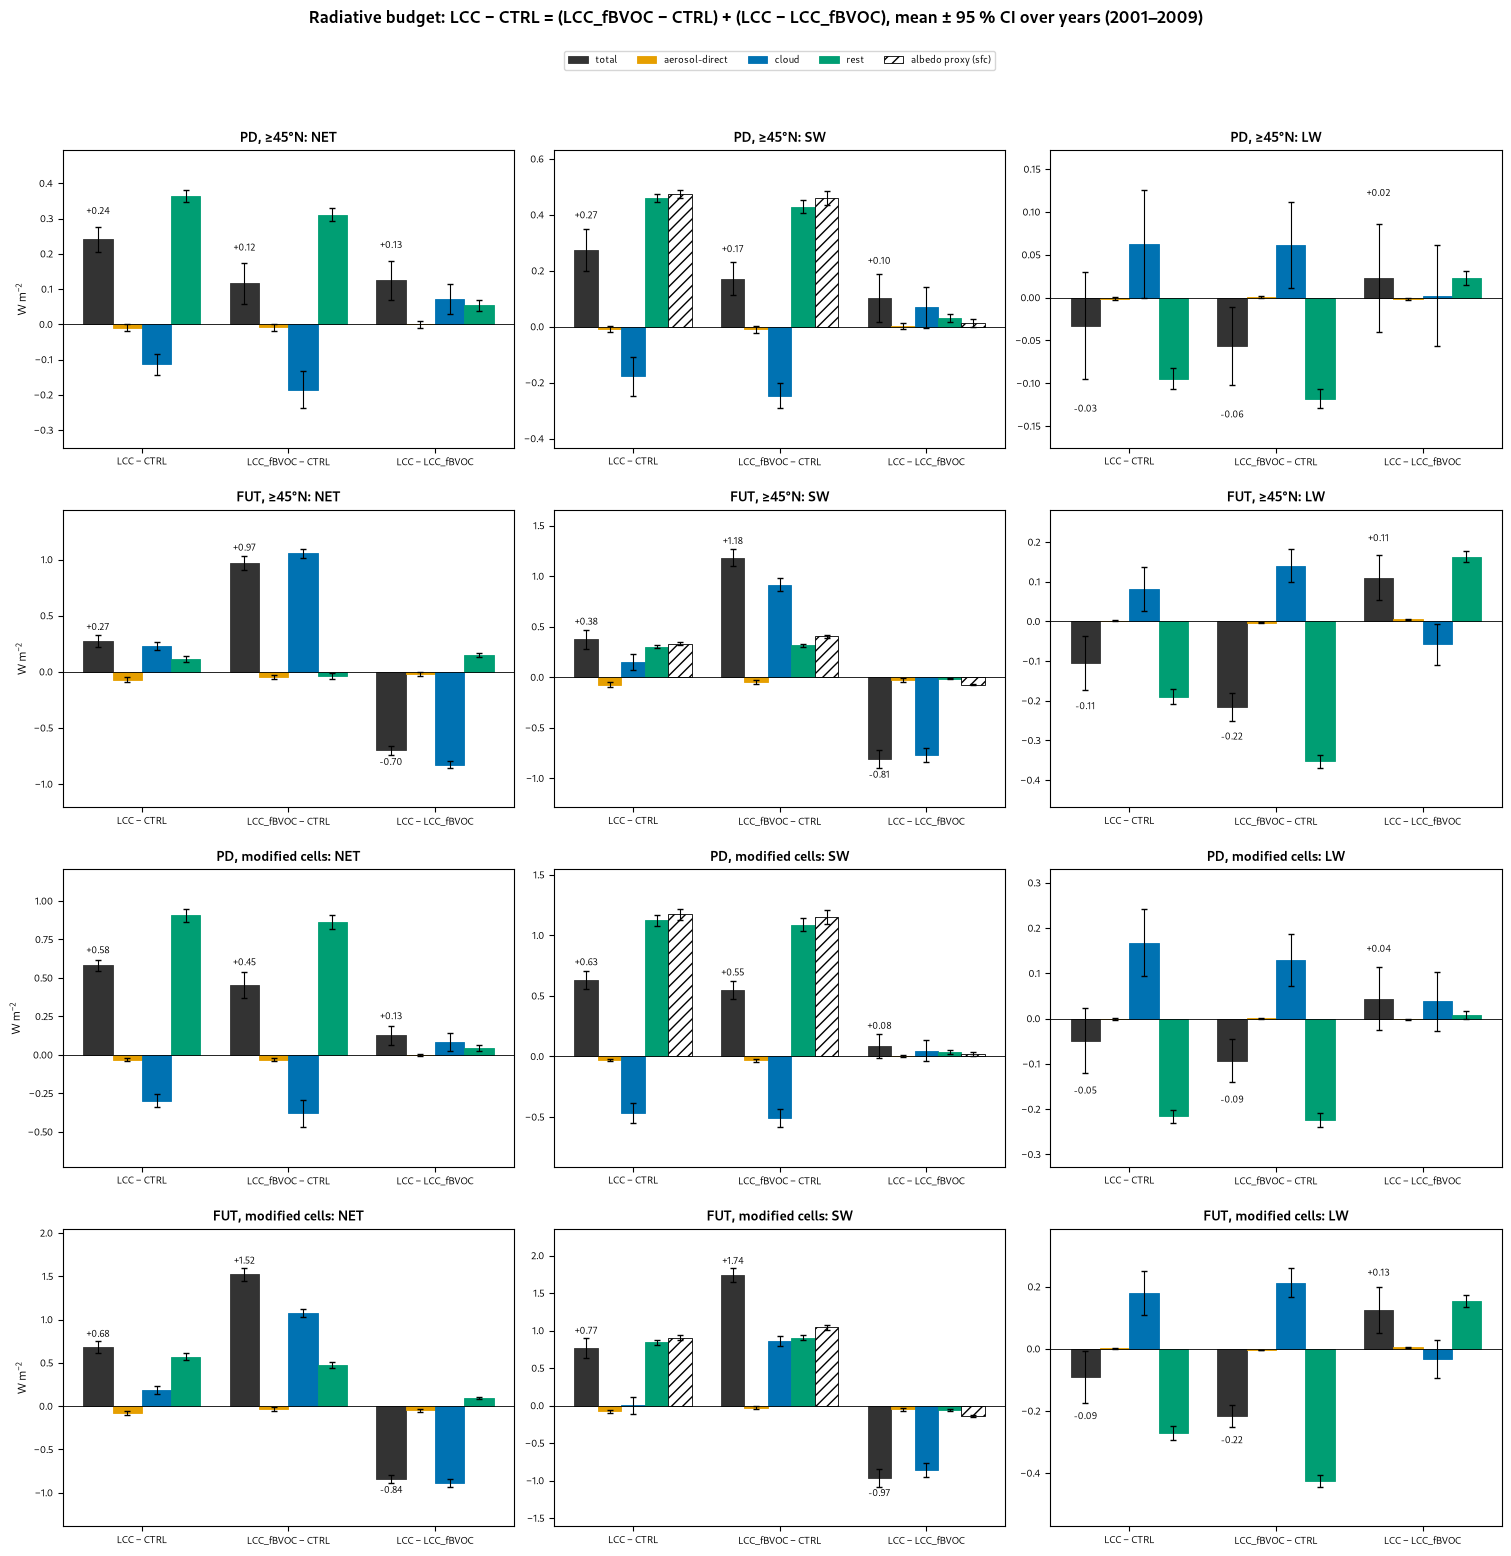

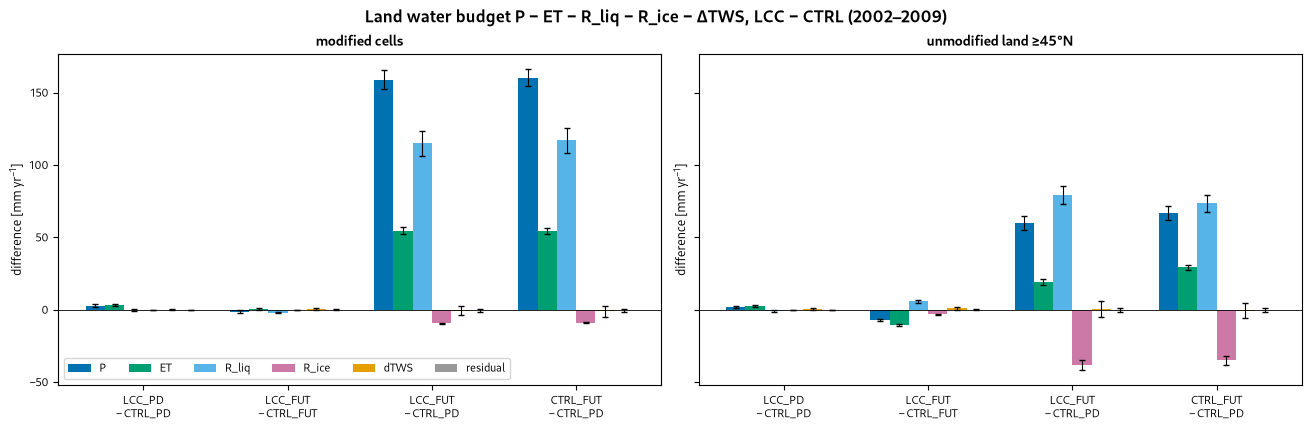

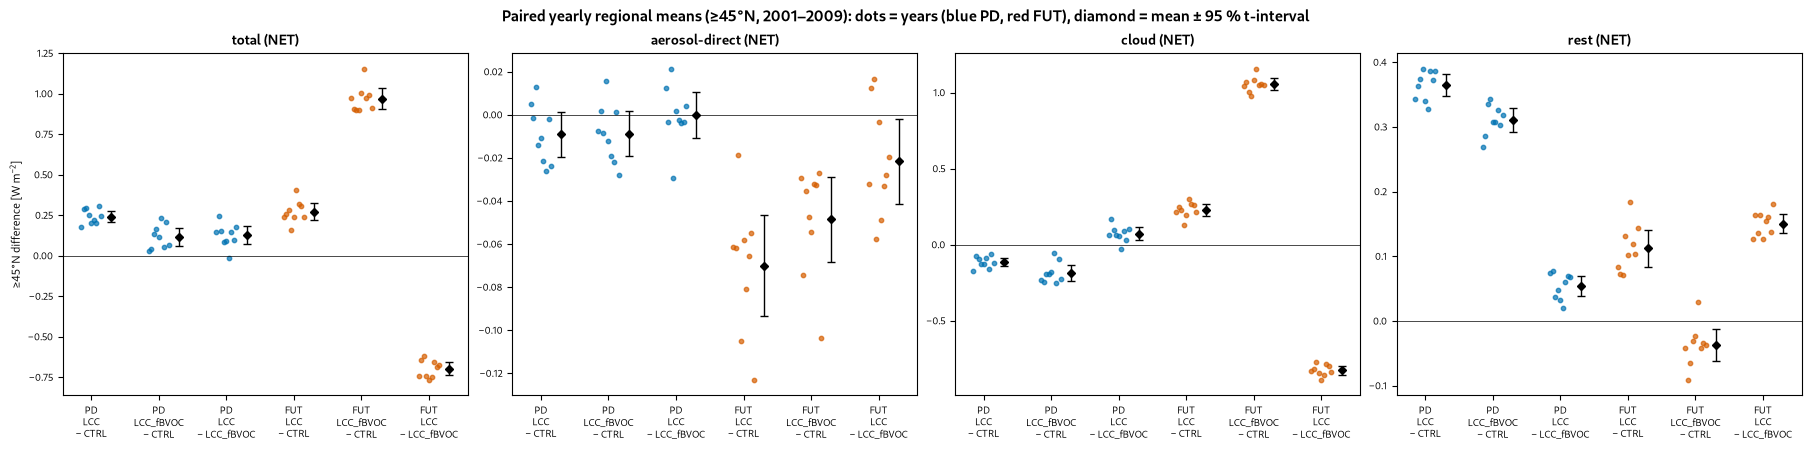

In [5]:
palette_figures("B_OkabeIto")

## C: Paul Tol 'bright'

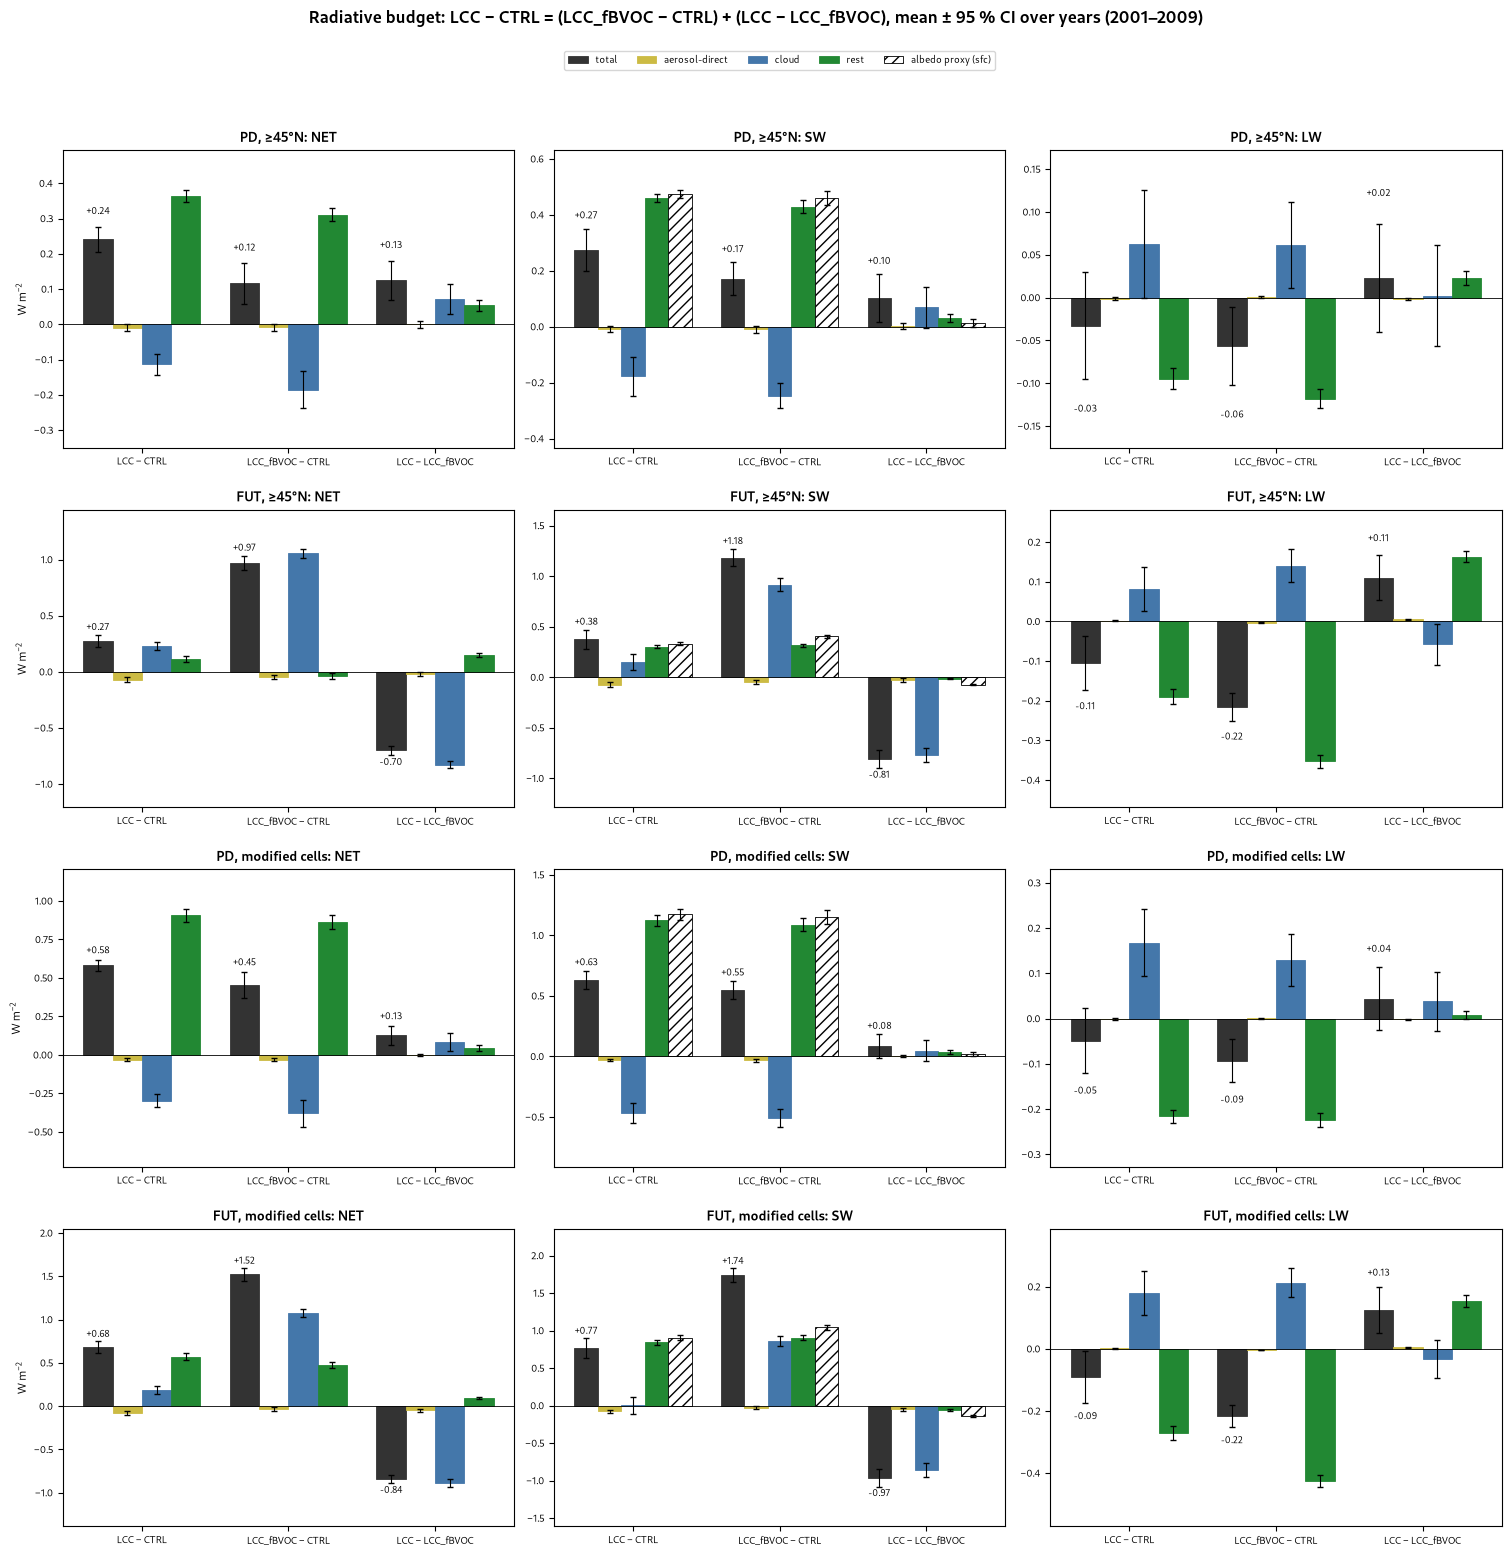

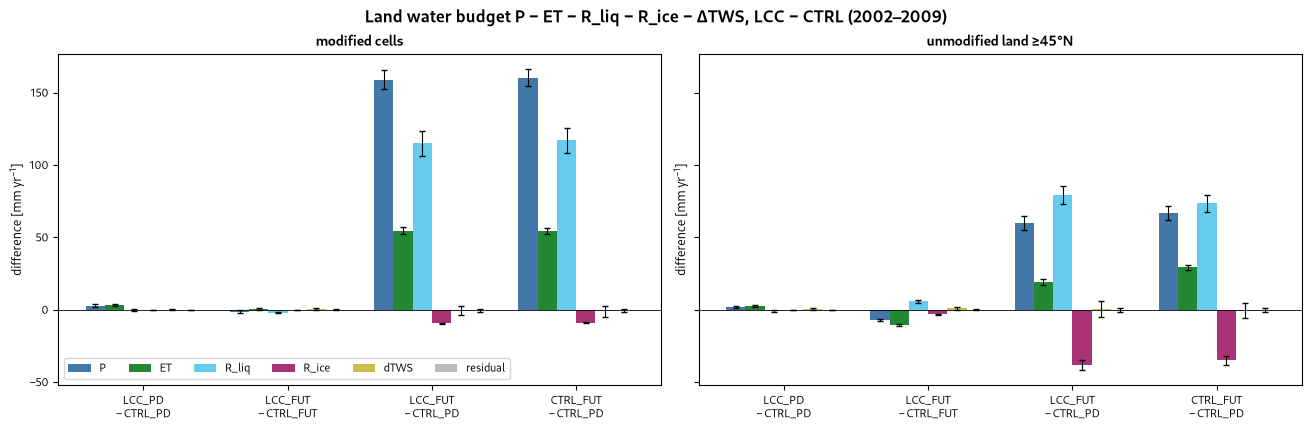

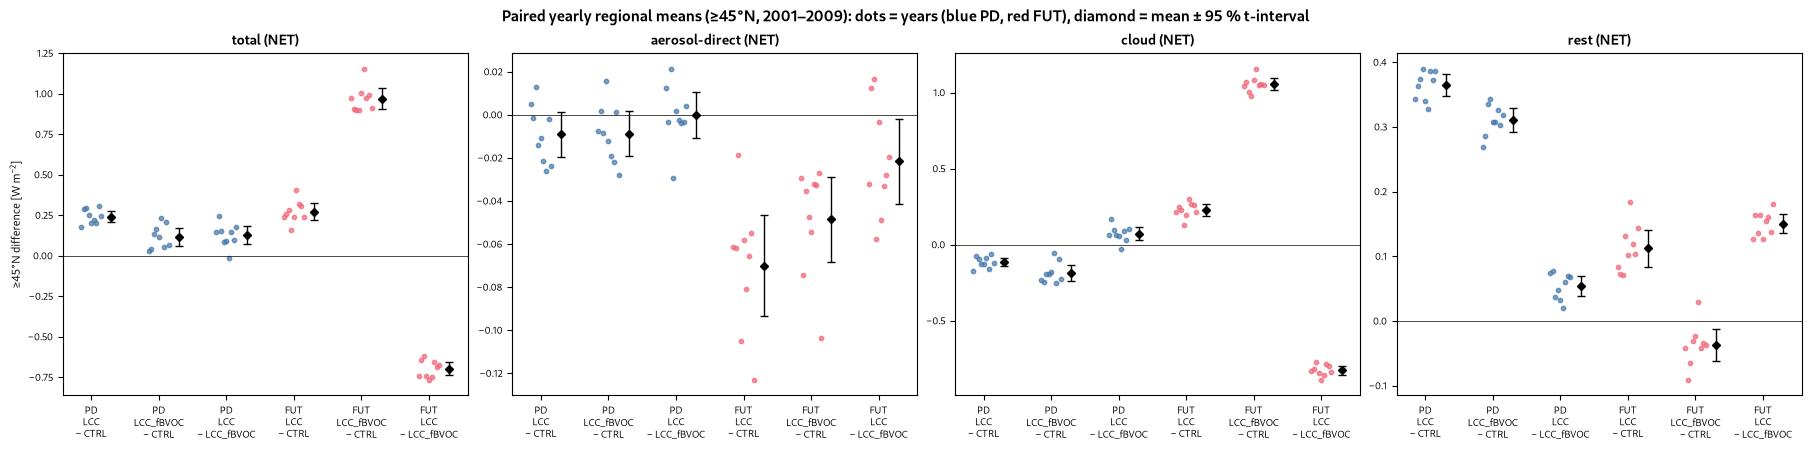

In [6]:
palette_figures("C_TolBright")

## D: Paul Tol 'muted' (soft)

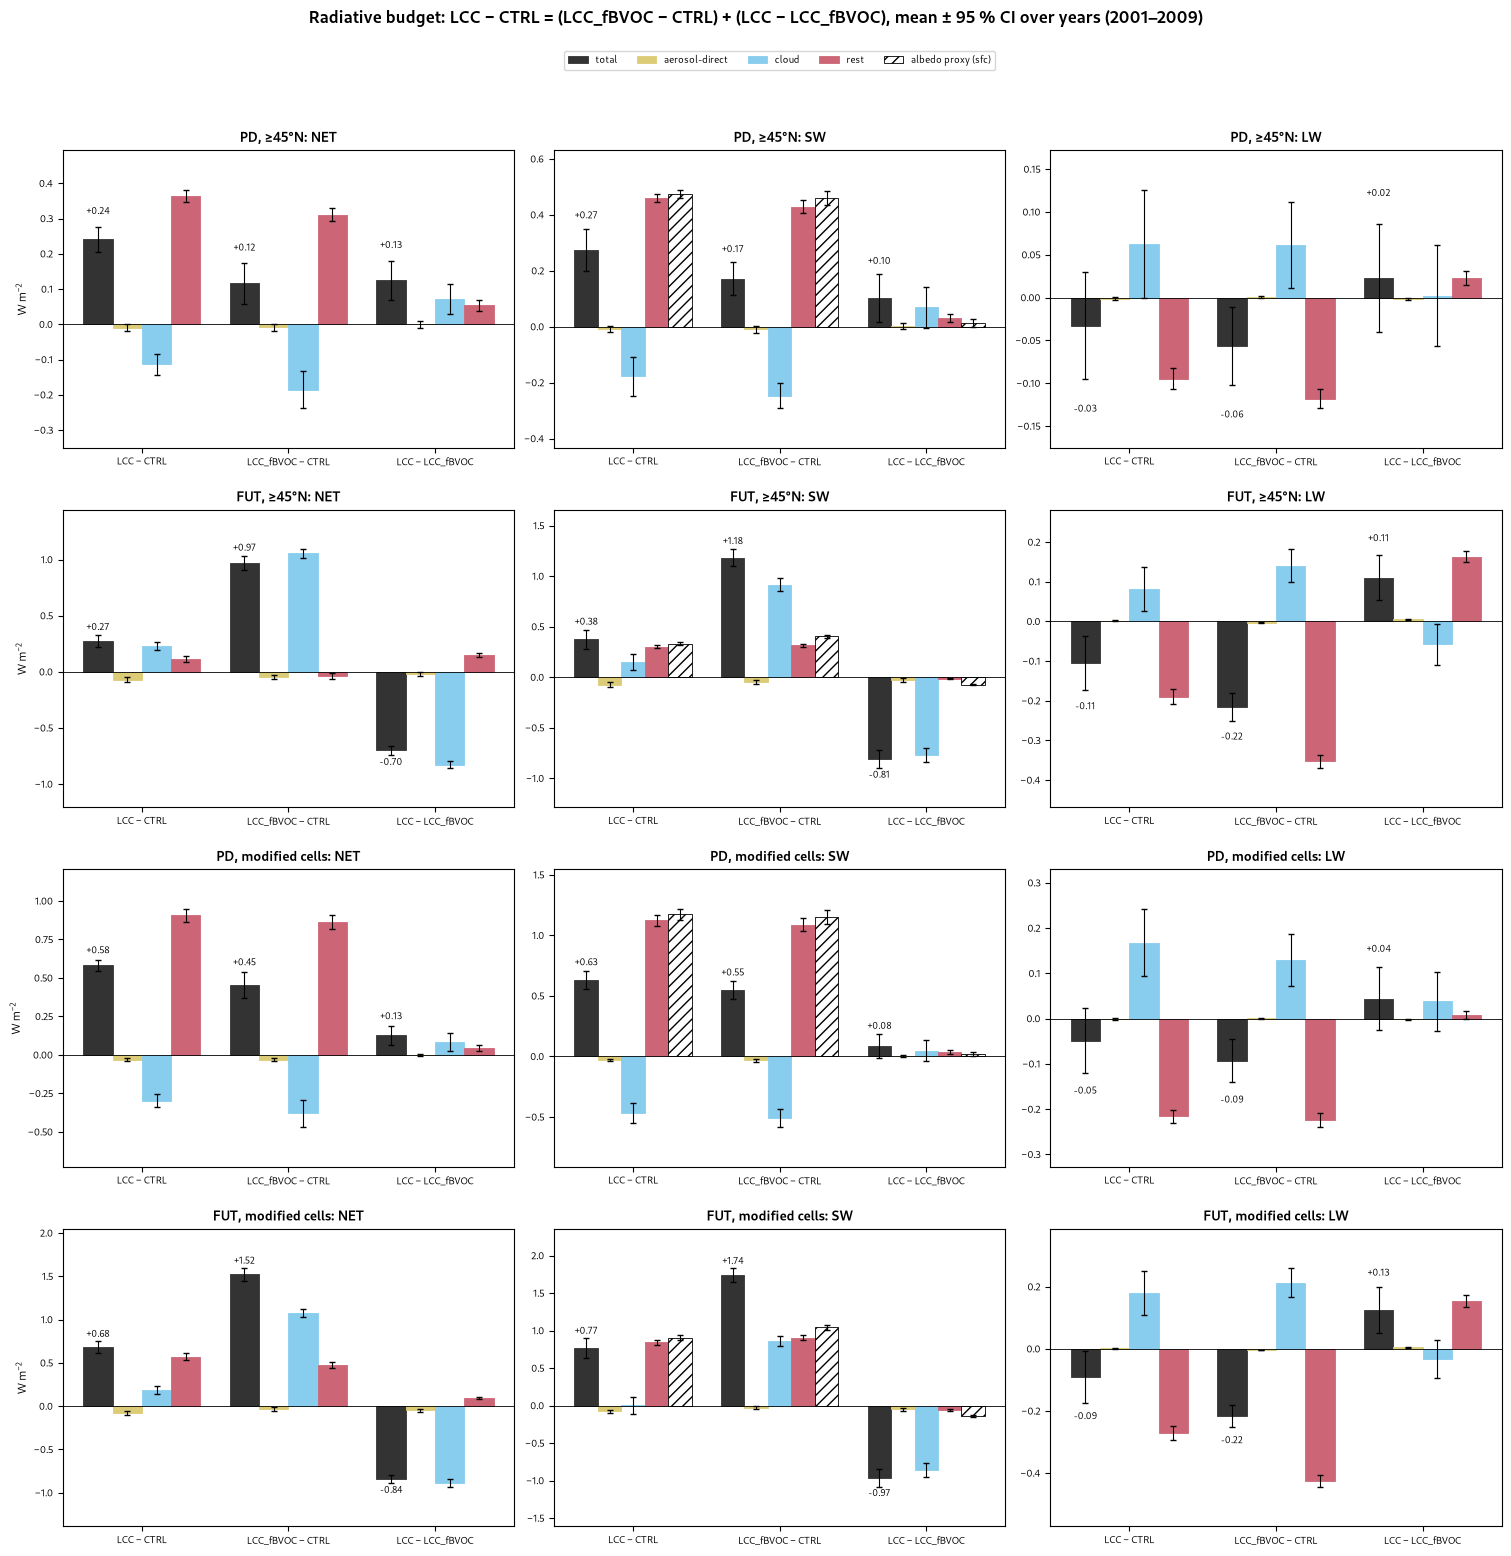

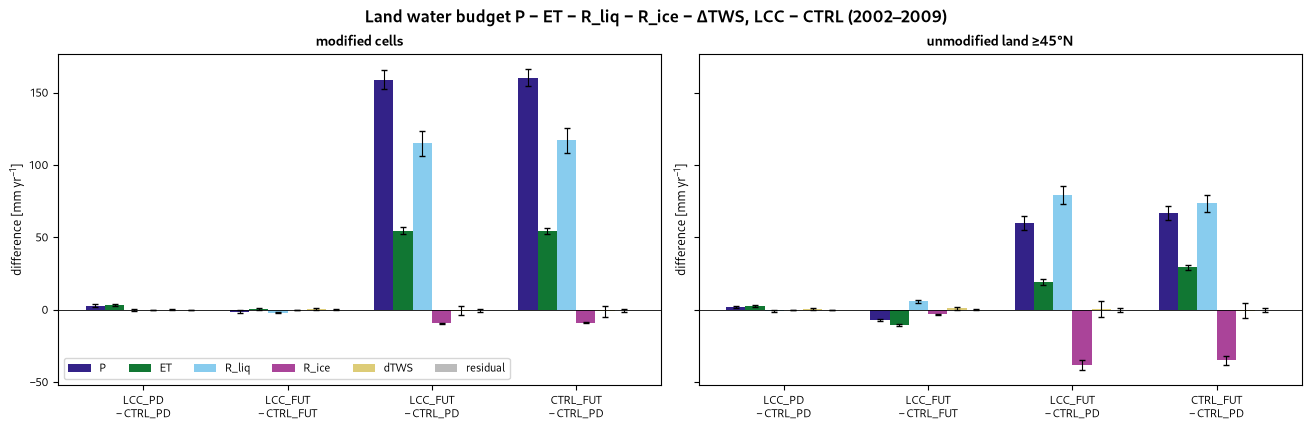

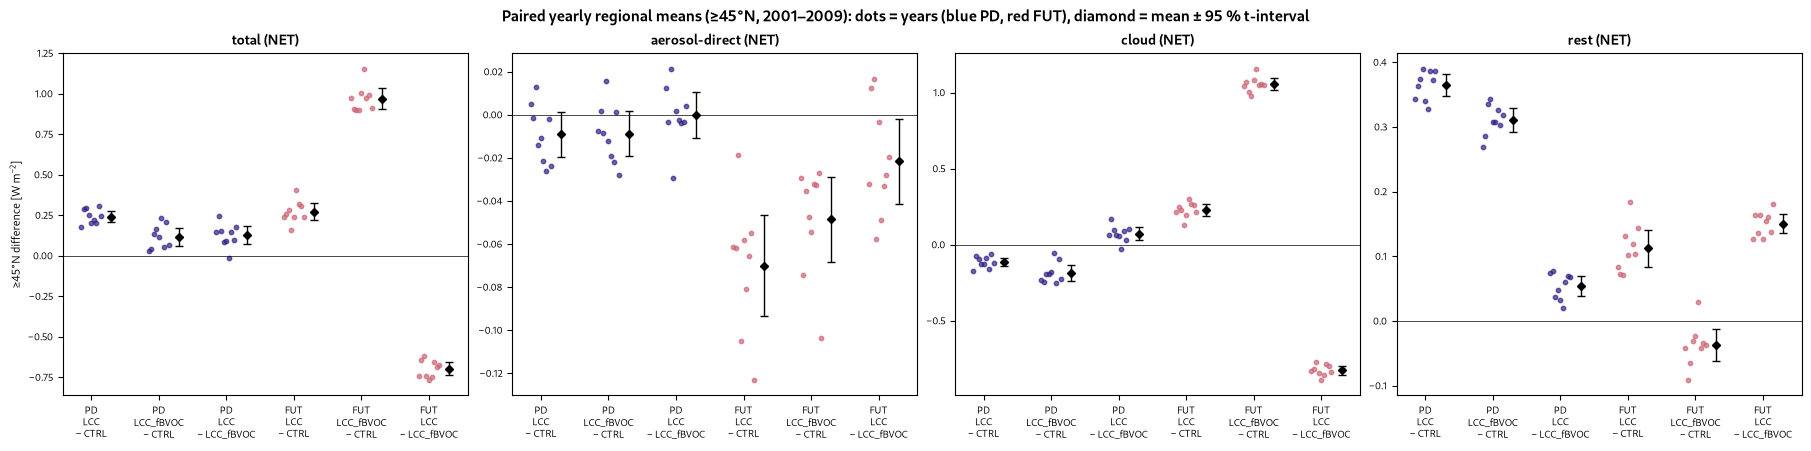

In [7]:
palette_figures("D_TolMuted")

## E: Paul Tol 'vibrant'

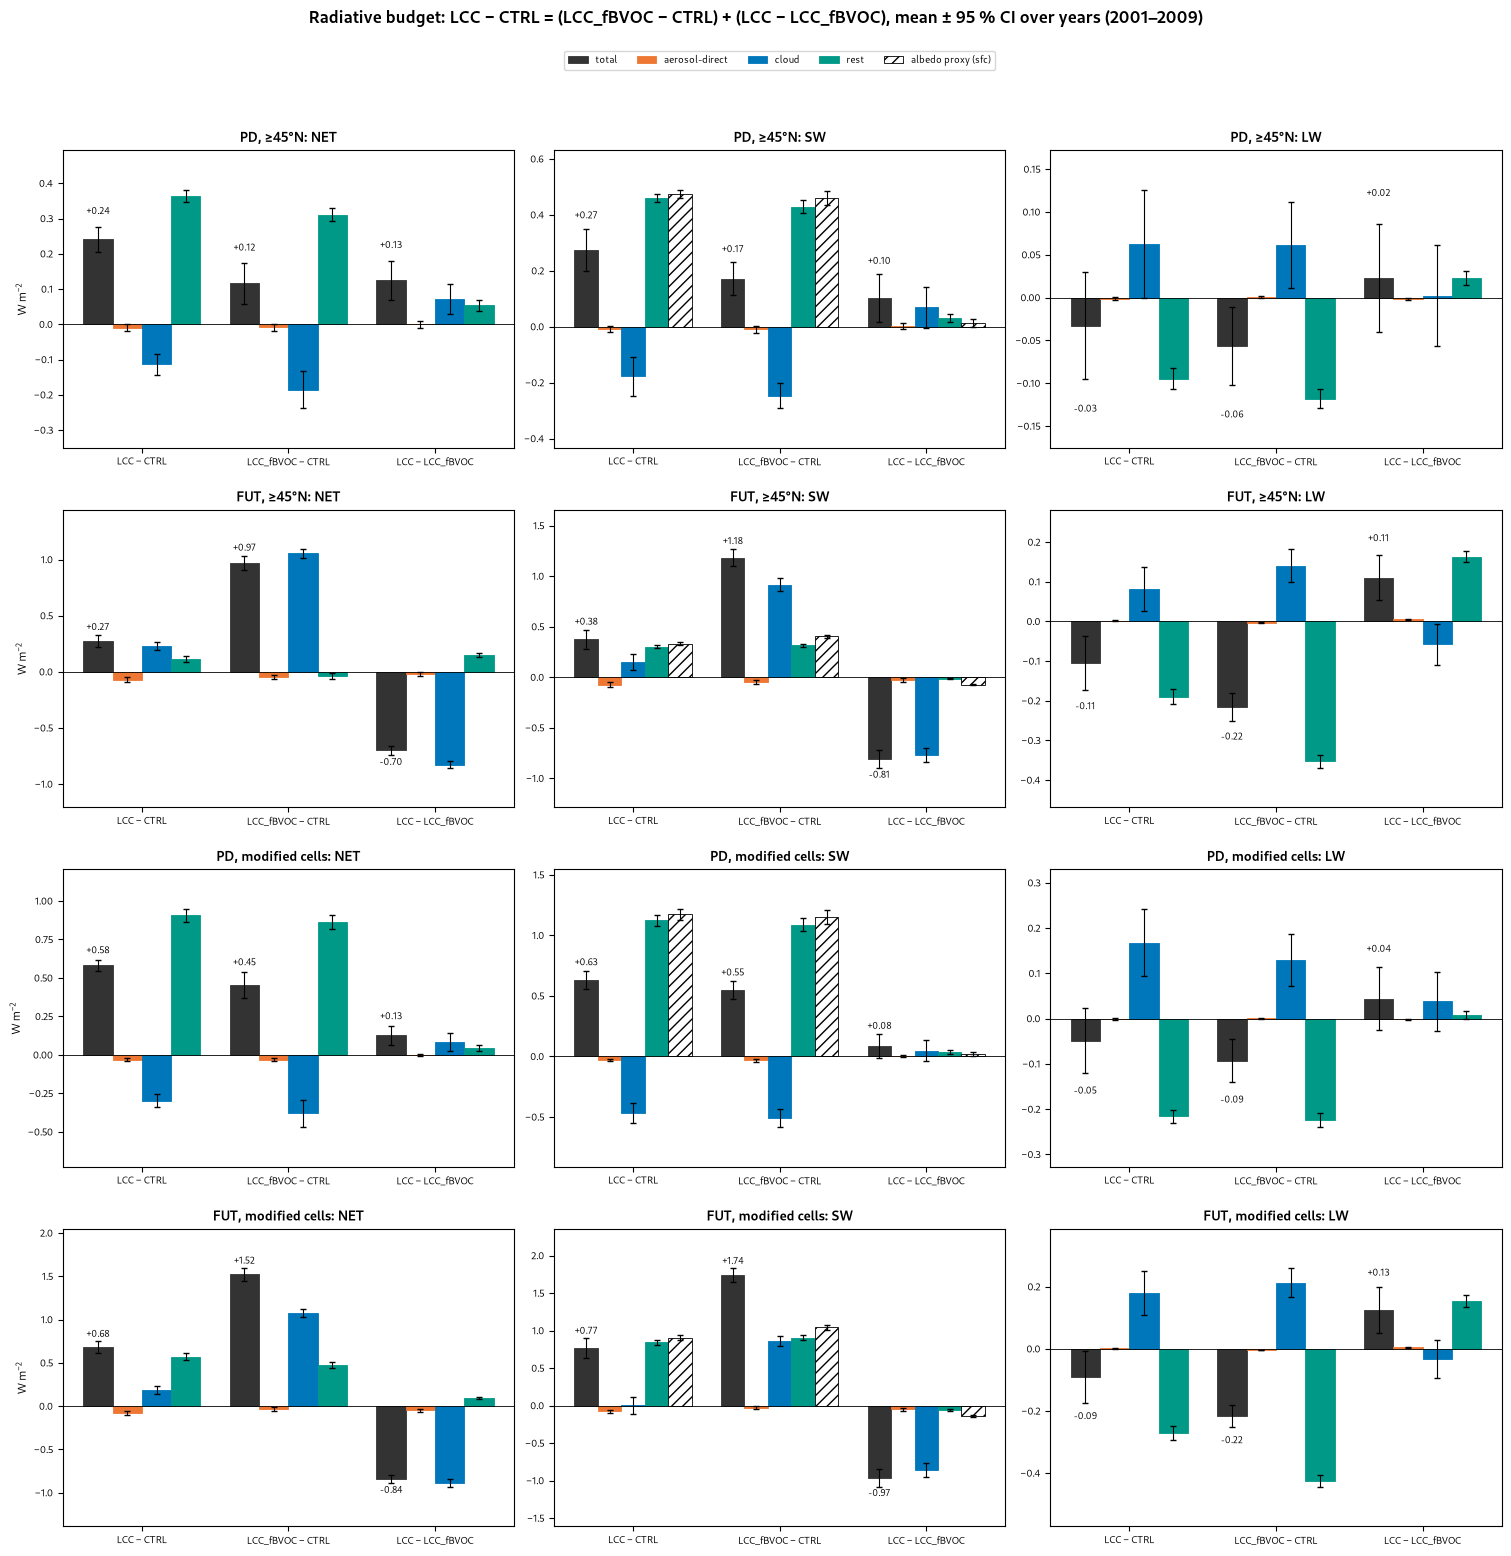

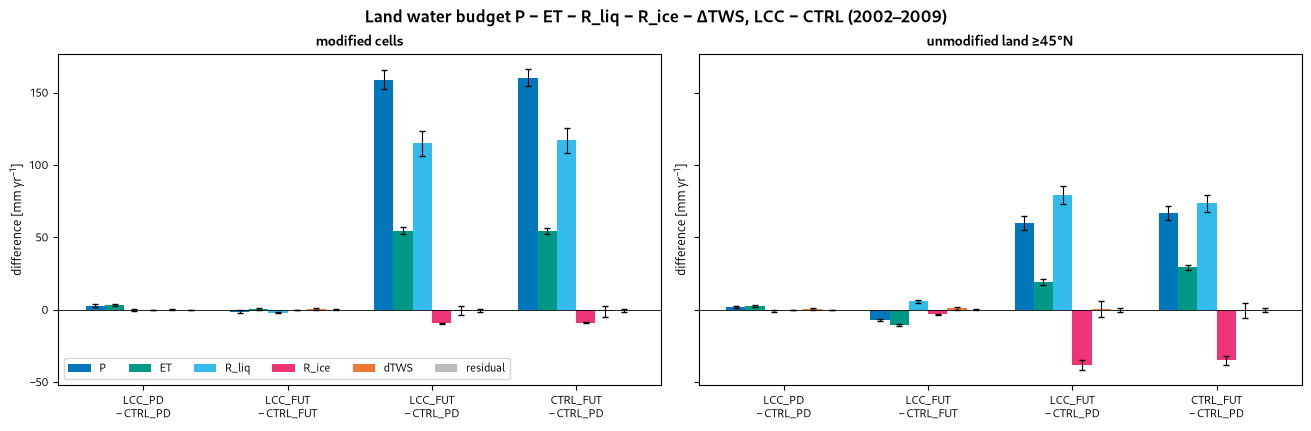

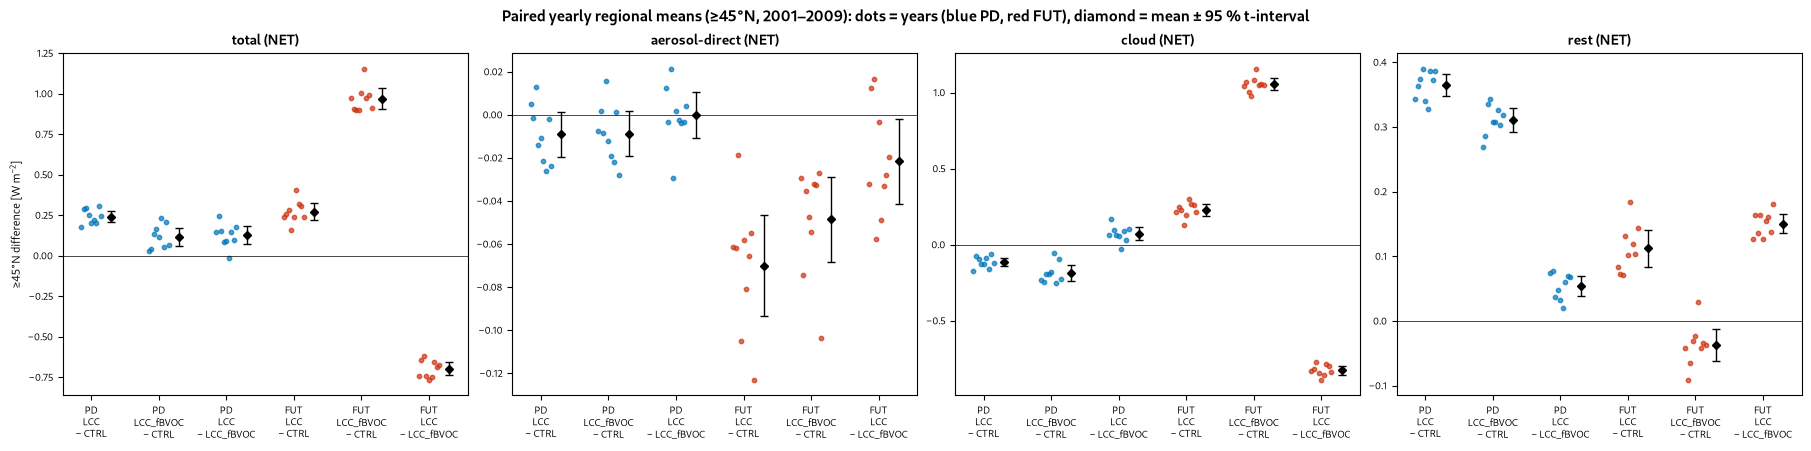

In [8]:
palette_figures("E_TolVibrant")

## F: dataviz reference palette

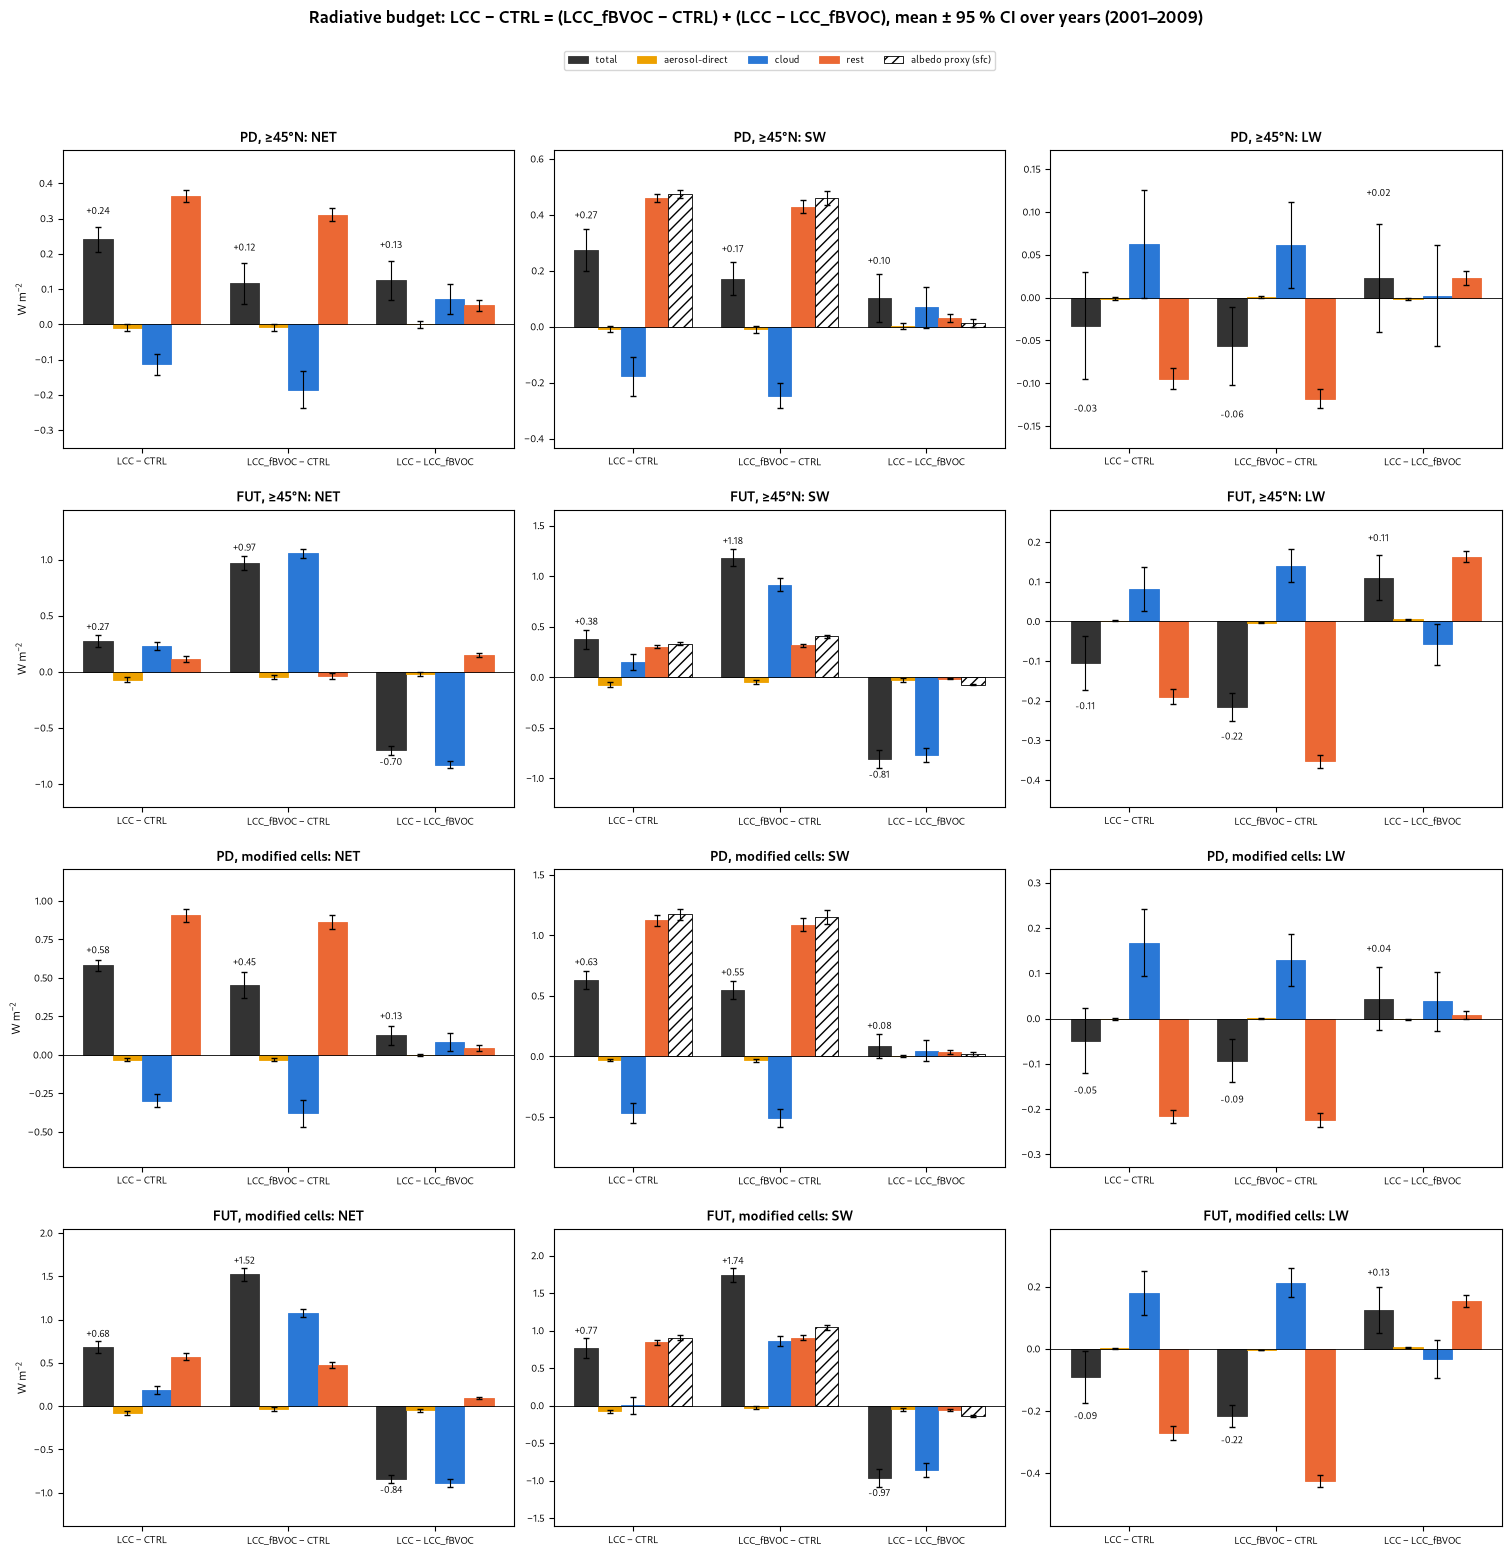

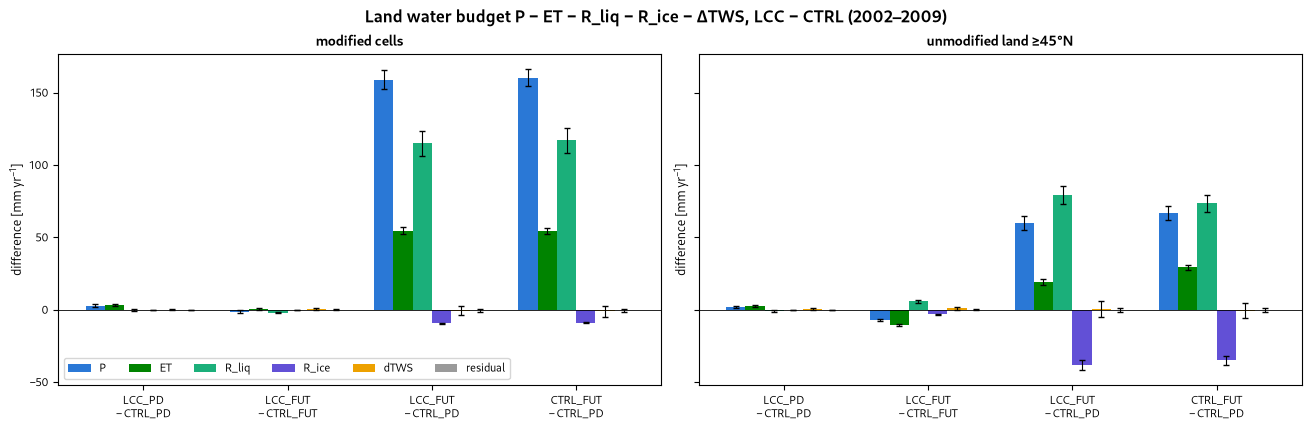

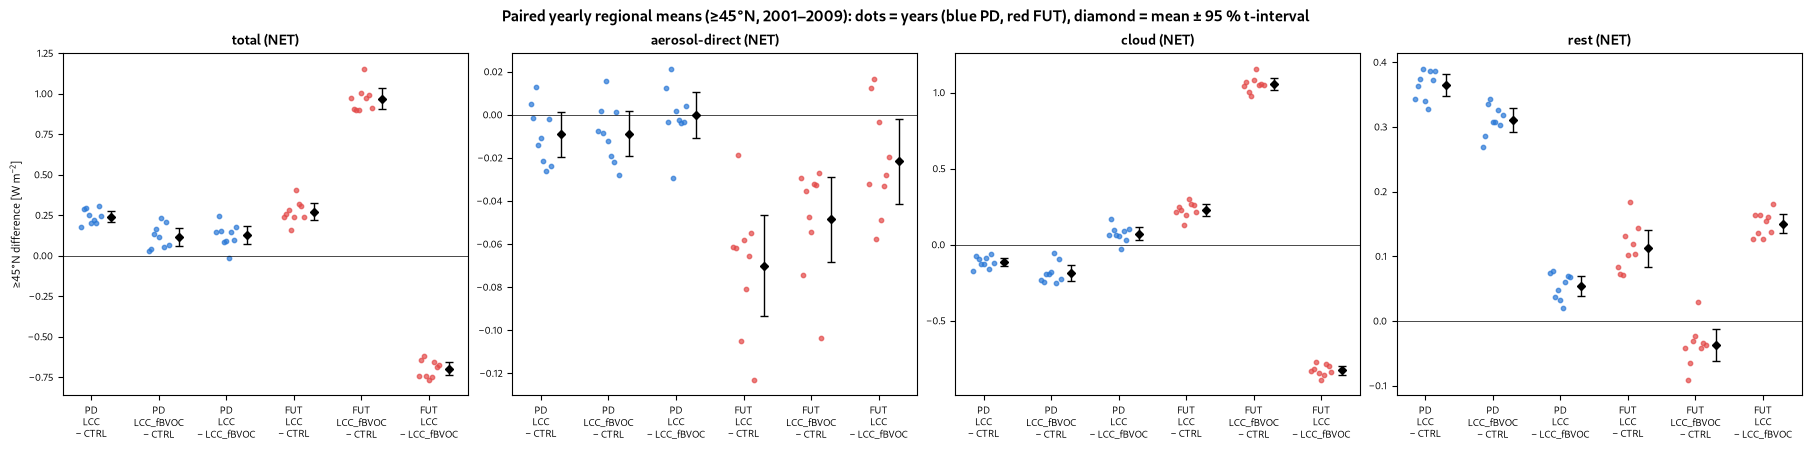

In [9]:
palette_figures("F_SkillDefault")